# Analysis of the test run

200 GSM8K test questions, 37 configs, 7,400 runs, with the pre-registered protocol
(`report/preregistration.json`, tag `pre-test-run`). H1–H8 are confirmatory
(`report/hypotheses.md`); everything else here is exploratory. Figures are written to
`report/figures/`.

The raw log is committed compressed (`results/test/grid.jsonl.gz`); the tables of
`scripts.summarize` and `scripts.confirmatory` are in `results/test/grid_*.csv|json`.

In [1]:
import json
import os
import sys
from collections import defaultdict
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch
from matplotlib.ticker import PercentFormatter

from scripts.confirmatory import run as confirmatory
from scripts.summarize import cell_of, group, method_rows
from src.logging_utils import read_records
from src.metrics import adoption, answers_match, bootstrap_ci, team_adopted

LOG = "results/test/grid.jsonl.gz"
FIGURES = ROOT / "report" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

records = read_records(LOG)
meta = read_records(LOG, "meta")[0]
end = read_records(LOG, "session_end")[0]
by_cfg = group(records)
pre = json.loads((ROOT / "report" / "preregistration.json").read_text())
assert meta["protocol_sha"] == pre["protocol_sha"] and meta["split"] == "test" and meta["limit"] is None
print(f"{len(records)} runs, {len(by_cfg)} configs, {end['failures']} failures, {end['wall_s'] / 3600:.1f} h; "
      f"protocol {meta['protocol_sha']} (pre-registered), commit {meta['git_commit'][:7]}")

7400 runs, 37 configs, 0 failures, 5.0 h; protocol 58917055adcf (pre-registered), commit 3d2d846


## Plot style

Light surface, thin marks, hairline grid, one fixed color per entity. The five-color set
of Fig. 3 (four hues and a dark neutral for *no defense*) was checked for color-vision
deficiencies on every pair; every point is also labelled directly.

In [2]:
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 1, "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "ytick.major.size": 0, "xtick.major.size": 0,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 12, "legend.frameon": False, "savefig.dpi": 200,
})


def percent_axis(ax, top):
    ax.set_ylim(0, top)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))


def rounded_bars(ax, centers, heights, color, width_pt=16, radius_pt=3):
    """Bars with a rounded data end and a square base; set the axis limits first."""
    fig = ax.figure
    fig.canvas.draw()
    (x0, y0), (x1, y1) = ax.transData.transform([(0, 0), (1, 1)])
    sx, sy = x1 - x0, y1 - y0  # pixels per data unit
    pt = fig.dpi / 72
    w, r, ry = width_pt * pt / sx, radius_pt * pt / sx, radius_pt * pt / sy
    for c, h in zip(centers, heights):
        if h > 0:  # the rounded base falls below y = 0 and is clipped by the axes
            ax.add_patch(FancyBboxPatch((c - w / 2, -ry), w, h + ry, boxstyle=f"round,pad=0,rounding_size={r}",
                                        mutation_aspect=sx / sy, facecolor=color, edgecolor="none"))
    return w


def cis(ax, xs, rows, color=INK2):
    for x, (_, lo, hi, *_) in zip(xs, rows):
        ax.vlines(x, lo, hi, color=color, linewidth=1)


def grouped_bars(ax, series, labels, gap_pt=2, width_pt=16, legend=None):
    """series: {name: ({key: (rate, lo, hi, n)}, color)}, bars side by side with a 2 pt gap."""
    x = np.arange(len(labels))
    ax.figure.canvas.draw()
    (x0, _), (x1, _) = ax.transData.transform([(0, 0), (1, 0)])
    step = (width_pt + gap_pt) * ax.figure.dpi / 72 / (x1 - x0)
    for i, (rows, color) in enumerate(series.values()):
        xs = x + (i - (len(series) - 1) / 2) * step
        rounded_bars(ax, xs, [v[0] for v in rows.values()], color, width_pt=width_pt)
        cis(ax, xs, rows.values())
        for xi, v in zip(xs, rows.values()):
            ax.annotate(f"{v[0]:.0%}", (xi, v[2]), xytext=(0, 4), textcoords="offset points", ha="center",
                        va="bottom", color=INK2, fontsize=9)
    ax.set_xticks(x, labels)
    ax.legend(handles=[Line2D([], [], color=c, marker="s", linestyle="", markersize=9, label=n)
                       for n, (_, c) in series.items()], **(legend or {"loc": "upper left"}))


def save(fig, name):
    fig.savefig(FIGURES / name, bbox_inches="tight")
    plt.show()

## Confirmatory tests: H1–H8

Sign-flip permutation tests on per-question differences (100,000 permutations, seed 0),
Holm correction over the family, alpha = 0.05. Positive differences go in the
pre-registered direction (adoption: first minus second; H8: hybrid minus aggregator
accuracy). H2, H4 and H6 are two-sided.

In [3]:
conf = confirmatory(records)
table = pd.DataFrame({
    "hypothesis": conf["description"].values,
    "test": conf["alternative"].map({"greater": "one-sided", "two-sided": "two-sided"}).values,
    "difference": [f"{d * 100:+.1f}" for d in conf["mean_difference"]],
    "95% CI": [f"[{lo * 100:+.1f}, {hi * 100:+.1f}]" for lo, hi in zip(conf["ci_low"], conf["ci_high"])],
    "p (Holm)": [f"{p:.4f}" for p in conf["p_holm"]],
    "supported": conf["supported"].map({True: "yes", False: "no"}).values,
}, index=conf["hypothesis"].values)
print("Differences in percentage points, n = 200 questions")
table

Differences in percentage points, n = 200 questions


,hypothesis,test,difference,95% CI,p (Holm),supported
H1,chain: team adoption higher with the faulty so...,one-sided,+22.8,"[+17.1, +28.2]",0.0001,yes
H2,persuasive vs neutral team adoption differ (ch...,two-sided,+1.9,"[-1.8, +5.5]",0.6835,no
H3,primacy: team adoption higher when the faulty ...,one-sided,+22.9,"[+17.4, +28.2]",0.0001,yes
H4,chain (chronological) vs star team adoption di...,two-sided,-1.9,"[-6.9, +2.9]",0.6835,no
H5,the verifier lowers team adoption compared wit...,one-sided,+15.8,"[+13.8, +17.9]",0.0001,yes
H6,verifier vs skeptical instruction team adoptio...,two-sided,+13.6,"[+11.4, +15.8]",0.0001,yes
H7,a majority vote adopts the error less than the...,one-sided,+17.6,"[+15.5, +19.8]",0.0001,yes
H8,the hybrid vote is more accurate than the LLM ...,one-sided,+10.5,"[+8.8, +12.2]",0.0001,yes


## Fig. 1 — Adoption by presentation rank

Team adoption of the injected answer by the rank at which the aggregator reads the faulty
solution, no defense, both fault styles. Star: three independent solvers. Chain
(rotated): the chronological chain, with the solutions shown to the aggregator in the
star's rotating order (Latin square over the three chain positions).

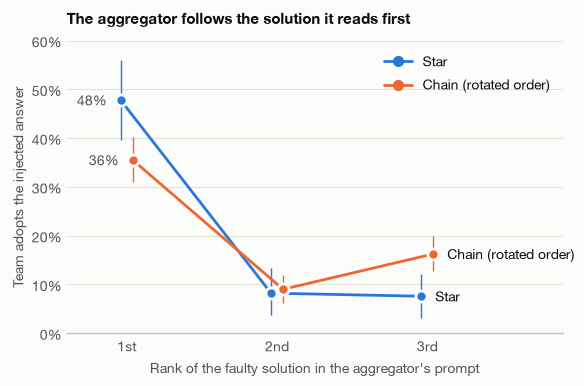

,Star,Chain (rotated order)
rank 1,"47.8% [39.6%, 56.0%] n=134","35.5% [31.0%, 40.2%] n=400"
rank 2,"8.2% [3.7%, 13.4%] n=134","9.0% [6.2%, 12.0%] n=400"
rank 3,"7.6% [3.0%, 12.1%] n=132","16.2% [12.8%, 20.0%] n=400"


In [4]:
def rank_rows(prefix):
    recs = [r for cid, rs in by_cfg.items() if cid.startswith(prefix) and cid.endswith("-none") for r in rs]
    out = {}
    for k in (1, 2, 3):
        x = [team_adopted(r) for r in recs if r["fault"] and r["fault"]["shown_at"] == k]
        out[k] = (*bootstrap_ci(x), len(x))
    return out


ranks = {"Star": (rank_rows("star-"), BLUE, -0.04), "Chain (rotated order)": (rank_rows("chain_rotated-"), ORANGE, 0.04)}
fig, ax = plt.subplots(figsize=(6.4, 3.8))
percent_axis(ax, 0.6)
for name, (rows, color, dx) in ranks.items():
    xs = [k + dx for k in rows]
    cis(ax, xs, rows.values(), color=color)
    ax.plot(xs, [v[0] for v in rows.values()], color=color, marker="o", markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=2, label=name)
    ax.annotate(f"{rows[1][0]:.0%}", (xs[0], rows[1][0]), xytext=(-10, 0), textcoords="offset points",
                ha="right", va="center", color=INK2)
    ax.annotate(name, (xs[-1], rows[3][0]), xytext=(10, 0), textcoords="offset points", va="center", color=INK)
ax.set_xticks([1, 2, 3], ["1st", "2nd", "3rd"])
ax.set_xlim(0.6, 3.9)
ax.set_xlabel("Rank of the faulty solution in the aggregator's prompt")
ax.set_ylabel("Team adopts the injected answer")
ax.set_title("The aggregator follows the solution it reads first")
ax.legend(handles=[Line2D([], [], color=c, marker="o", markersize=7, label=n) for n, (_, c, _) in ranks.items()],
          loc="upper right")
save(fig, "fig1_adoption_by_rank.png")
pd.DataFrame({name: {f"rank {k}": f"{v[0]:.1%} [{v[1]:.1%}, {v[2]:.1%}] n={v[3]}" for k, v in rows.items()}
              for name, (rows, _, _) in ranks.items()})

## Fig. 2 — Adoption by agent, chain with the faulty solver at p1

Share of runs in which each agent downstream of the faulty solver ends with the injected
answer (no defense). Solvers 2 and 3 read the faulty solution and write their own; the
aggregator reads all three.

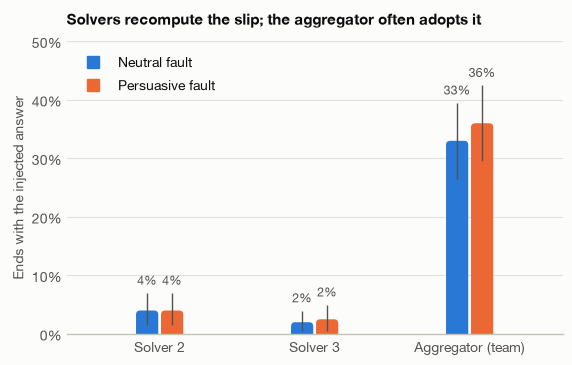

,Neutral fault,Persuasive fault
Solver 2,"4.0% [1.5%, 7.0%]","4.0% [1.5%, 7.0%]"
Solver 3,"2.0% [0.5%, 4.0%]","2.5% [0.5%, 5.0%]"
Aggregator (team),"33.0% [26.5%, 39.5%]","36.0% [29.5%, 42.5%]"


In [5]:
AGENTS = {"solver2": "Solver 2", "solver3": "Solver 3", "aggregator": "Aggregator (team)"}


def agent_rates(recs, wrong_of):
    out = {}
    for aid in AGENTS:
        x = []
        for r in recs:
            wrong = wrong_of(r)
            if wrong is None:
                continue
            m = next(m for m in r["messages"] if m["agent_id"] == aid)
            x.append(answers_match(m["parsed_answer"], wrong))
        out[aid] = (*bootstrap_ci(x), len(x))
    return out


injected = lambda r: r["fault"]["wrong_answer"]  # noqa: E731
styles = {"Neutral fault": (agent_rates(by_cfg["chain-neutral-p1-none"], injected), BLUE),
          "Persuasive fault": (agent_rates(by_cfg["chain-persuasive-p1-none"], injected), ORANGE)}

fig, ax = plt.subplots(figsize=(6.4, 3.8))
percent_axis(ax, 0.5)
ax.set_xlim(-0.6, 2.6)
grouped_bars(ax, styles, AGENTS.values())
ax.set_ylabel("Ends with the injected answer")
ax.set_title("Solvers recompute the slip; the aggregator often adopts it")
save(fig, "fig2_adoption_by_agent.png")
pd.DataFrame({n: {AGENTS[a]: f"{v[0]:.1%} [{v[1]:.1%}, {v[2]:.1%}]" for a, v in rows.items()}
              for n, (rows, _) in styles.items()})

## Fig. 3 — Defenses: accuracy with a fault against cost

Accuracy (final answer correct) over the fault configs of each topology (chain: two
styles x three positions; star: two styles), against tokens per question. *Majority* and
*hybrid* votes are computed on the no-defense runs, with no extra LLM call: majority =
strict majority of the solvers (none = wrong); hybrid = the majority if there is one,
otherwise the LLM aggregator's answer, counting the aggregator's tokens only when it is
needed.

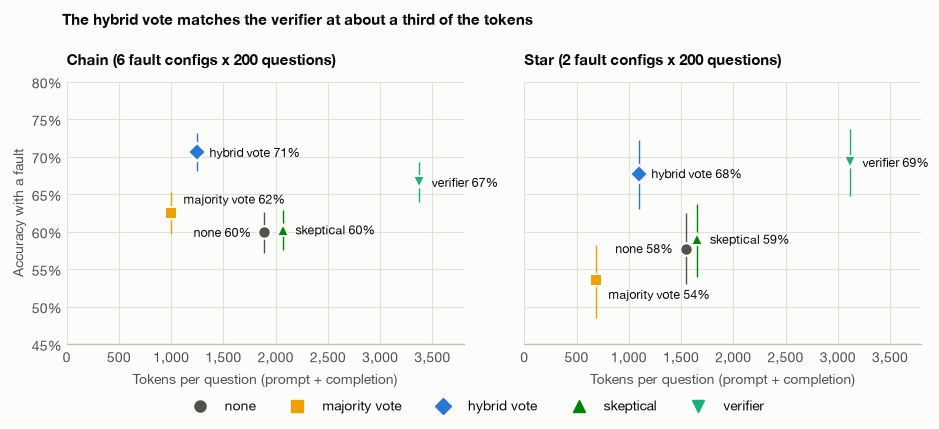

chain                                \
                           accuracy team adopted calls/q tokens/q   
none           59.9% [57.2%, 62.7%]        19.3%     3.0     1889   
majority vote  62.5% [59.8%, 65.2%]         2.9%     2.0      998   
hybrid vote    70.6% [68.1%, 73.2%]         8.9%     2.3     1247   
skeptical      60.2% [57.5%, 62.9%]        17.7%     3.0     2070   
verifier       66.6% [63.9%, 69.2%]         3.7%     6.0     3373   

                               star                                
                           accuracy team adopted calls/q tokens/q  
none           57.8% [53.0%, 62.5%]        21.2%     3.0     1545  
majority vote  53.5% [48.5%, 58.2%]         0.0%     2.0      685  
hybrid vote    67.8% [63.0%, 72.2%]        12.8%     2.4     1096  
skeptical      59.0% [54.0%, 63.7%]        17.5%     3.0     1658  
verifier       69.2% [64.8%, 73.8%]         5.0%     6.0     3116

In [6]:
METHODS = {  # color, marker
    "none": ("#52514e", "o"), "majority vote": ("#eda100", "s"), "hybrid vote": (BLUE, "D"),
    "skeptical": ("#008300", "^"), "verifier": ("#1baf7a", "v"),
}
LABEL_OFFSET = {  # (dx, dy) in points, alignment; placed by hand to avoid the error bars
    ("chain", "none"): (-9, 0, "right"), ("star", "none"): (-9, 0, "right"),
    ("chain", "majority vote"): (9, 10, "left"), ("star", "majority vote"): (9, -10, "left"),
}


def pooled_methods(topology):
    by_def = defaultdict(list)
    for recs in by_cfg.values():
        c = recs[0]["config"]
        if c["topology"] == topology and c.get("fault", "none") != "none":
            by_def[c.get("defense", "none")] += [{**r, "question_id": f"{r['question_id']}|{cell_of(r)}"} for r in recs]
    return {row["method"]: row for row in method_rows(by_def)}


pooled = {"chain": pooled_methods("chain"), "star": pooled_methods("star")}
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.0), sharey=True)
for ax, (topo, rows) in zip(axes, pooled.items()):
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_ylim(0.45, 0.80)
    ax.set_xlim(0, 3800)
    for name, (color, marker) in METHODS.items():
        row = rows[name]
        acc, lo, hi = row["recovery"]
        ax.vlines(row["tokens_per_q"], lo, hi, color=color, linewidth=1)
        ax.plot(row["tokens_per_q"], acc, marker=marker, markersize=9, color=color,
                markeredgecolor=SURFACE, markeredgewidth=1.5, linestyle="")
        dx, dy, ha = LABEL_OFFSET.get((topo, name), (9, 0, "left"))
        ax.annotate(f"{name} {acc:.0%}", (row["tokens_per_q"], acc), xytext=(dx, dy), textcoords="offset points",
                    ha=ha, va="center", color=INK, fontsize=9)
    n_cfg = rows["none"]["n"] // 200
    ax.set_title(f"{topo.capitalize()} ({n_cfg} fault configs x 200 questions)")
    ax.set_xlabel("Tokens per question (prompt + completion)")
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
axes[0].set_ylabel("Accuracy with a fault")
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
fig.legend(handles=[Line2D([], [], color=c, marker=m, linestyle="", markersize=8, label=n)
                    for n, (c, m) in METHODS.items()], loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("The hybrid vote matches the verifier at about a third of the tokens", x=0.07, ha="left",
             fontsize=11, fontweight="bold")
fig.tight_layout()
save(fig, "fig3_defenses_cost.png")
pd.DataFrame({(topo, k): {name: v for name, v in zip(METHODS, vals)} for topo, rows in pooled.items()
              for k, vals in (
                  ("accuracy", [f"{rows[m]['recovery'][0]:.1%} [{rows[m]['recovery'][1]:.1%}, {rows[m]['recovery'][2]:.1%}]" for m in METHODS]),
                  ("team adopted", [f"{rows[m]['rate'][0]:.1%}" for m in METHODS]),
                  ("calls/q", [f"{rows[m]['calls_per_q']:.1f}" for m in METHODS]),
                  ("tokens/q", [f"{rows[m]['tokens_per_q']:.0f}" for m in METHODS]))})

Accuracy without a fault, for the same methods (no-fault configs, 200 questions each):

In [7]:
no_fault = {}
for topo in ("chain", "star"):
    by_def = {d: by_cfg[f"{topo}-none-{d}"] for d in ("none", "skeptical", "verifier")}
    no_fault[topo] = {row["method"]: f"{row['rate'][0]:.1%} [{row['rate'][1]:.1%}, {row['rate'][2]:.1%}]"
                      for row in method_rows(by_def)}
pd.DataFrame(no_fault).loc[list(METHODS)]

,chain,star
none,"71.0% [64.5%, 77.0%]","72.5% [66.0%, 78.5%]"
majority vote,"71.5% [65.0%, 77.5%]","70.0% [63.5%, 76.5%]"
hybrid vote,"72.5% [66.5%, 78.5%]","77.0% [71.0%, 82.5%]"
skeptical,"67.0% [60.5%, 73.5%]","76.0% [70.0%, 81.5%]"
verifier,"72.0% [65.5%, 78.0%]","74.0% [68.0%, 80.0%]"


## Fig. 4 — Natural against injected propagation

Chain, no defense. *Natural*: runs without injected fault where solver 1 is wrong on its
own (strict parser); share of downstream agents ending with solver 1's wrong answer.
*Injected*: the faulty solver at p1 (both styles); share ending with the injected answer.
The reference line is the coincidence baseline: in the star without fault, how often an
independent solver (one that never read solver 1) gives the same wrong answer as solver 1.

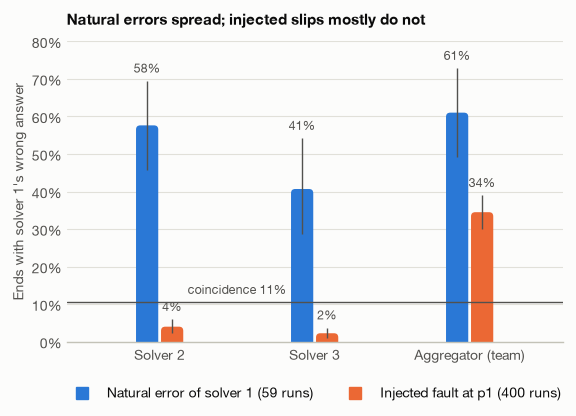

coincidence baseline (star, independent solvers, 57 runs): 10.5% [4.4%, 17.5%]


,Natural error of solver 1 (59 runs),Injected fault at p1 (400 runs)
Solver 2,"57.6% [45.8%, 69.5%]","4.0% [2.2%, 6.0%]"
Solver 3,"40.7% [28.8%, 54.2%]","2.2% [1.0%, 3.8%]"
Aggregator (team),"61.0% [49.2%, 72.9%]","34.5% [30.0%, 39.0%]"


In [8]:
def natural_wrong(r):
    a = next(m for m in r["messages"] if m["agent_id"] == "solver1")["parsed_answer"]
    return a if a is not None and not answers_match(a, r["gold"]) else None


natural = agent_rates(by_cfg["chain-none-none"], natural_wrong)
injected_both = agent_rates(by_cfg["chain-neutral-p1-none"] + by_cfg["chain-persuasive-p1-none"], injected)
control = adoption(by_cfg["star-none-none"], source="solver1")  # independent solvers 2 and 3
coincidence = (control["control_rate"], *control["control_ci"])

series = {f"Natural error of solver 1 ({natural['solver2'][3]} runs)": (natural, BLUE),
          f"Injected fault at p1 ({injected_both['solver2'][3]} runs)": (injected_both, ORANGE)}
fig, ax = plt.subplots(figsize=(6.4, 3.9))
percent_axis(ax, 0.8)
ax.set_xlim(-0.6, 2.6)
grouped_bars(ax, series, AGENTS.values(), legend={"loc": "upper center", "bbox_to_anchor": (0.5, -0.1), "ncol": 2})
ax.axhline(coincidence[0], color=INK2, linewidth=1, zorder=1)
ax.annotate(f"coincidence {coincidence[0]:.0%}", (0.5, coincidence[0]), xytext=(0, 4), textcoords="offset points",
            ha="center", va="bottom", color=INK2, fontsize=9)
ax.set_ylabel("Ends with solver 1's wrong answer")
ax.set_title("Natural errors spread; injected slips mostly do not")
save(fig, "fig4_natural_vs_injected.png")
print(f"coincidence baseline (star, independent solvers, {control['n_cases']} runs): {coincidence[0]:.1%} "
      f"[{coincidence[1]:.1%}, {coincidence[2]:.1%}]")
pd.DataFrame({n: {AGENTS[a]: f"{v[0]:.1%} [{v[1]:.1%}, {v[2]:.1%}]" for a, v in rows.items()}
              for n, (rows, _) in series.items()})

## Exploratory: correction by downstream solvers

On dev, the chain_rotated runs suggested that a fault at p1 is adopted less than the same
fault at p3 *at equal presentation rank*, as if solvers 2 and 3, who read it, helped
the aggregator to reject it. Estimate: the difference p3 − p1 in team adoption within
each rank, averaged over the three ranks (questions resampled for the CI). The dev
point estimate comes from the committed dev table (the raw dev log is not committed).

In [9]:
rotated = [r for cid, rs in by_cfg.items() if cid.startswith("chain_rotated-") for r in rs]
qids = sorted({r["question_id"] for r in rotated})
index = {q: i for i, q in enumerate(qids)}
cells = defaultdict(list)
for r in rotated:
    cells[(r["fault"]["position"], r["fault"]["shown_at"])].append((index[r["question_id"]], team_adopted(r)))
cells = {k: (np.array([i for i, _ in v]), np.array([a for _, a in v], float)) for k, v in cells.items()}


def correction(weights):
    """Mean over ranks of adoption(p3) - adoption(p1), questions weighted for the bootstrap."""
    rate = {k: np.average(a, weights=weights[i]) for k, (i, a) in cells.items()}
    return float(np.mean([rate[(3, k)] - rate[(1, k)] for k in (1, 2, 3)]))


rng = np.random.default_rng(0)
boot = []
for _ in range(5000):
    weights = np.bincount(rng.integers(0, len(qids), len(qids)), minlength=len(qids))
    try:
        boot.append(correction(weights))
    except ZeroDivisionError:  # a resample without any question in some cell
        pass
test_est = correction(np.ones(len(qids)))
dev_rank = json.loads((ROOT / "results/dev/phase3_propagation_propagation.json").read_text())["position_rank"]
dev_est = np.mean([dev_rank["p3"][f"rank{k}"][0] - dev_rank["p1"][f"rank{k}"][0] for k in (1, 2, 3)])
print(f"p3 - p1 at equal rank: dev {dev_est * 100:+.1f} points (50 questions); "
      f"test {test_est * 100:+.1f} points [{np.quantile(boot, 0.025) * 100:+.1f}, {np.quantile(boot, 0.975) * 100:+.1f}]")
pd.DataFrame({f"p{p}": {f"rank {k}": f"{cells[(p, k)][1].mean():.0%}" for k in (1, 2, 3)} for p in (1, 2, 3)})

p3 - p1 at equal rank: dev +6.0 points (50 questions); test +1.6 points [-3.9, +7.2]


,p1,p2,p3
rank 1,32%,38%,36%
rank 2,7%,10%,11%
rank 3,17%,19%,13%


## Exploratory: dev against test

The single agent is much weaker on test than on dev, although the two sets look alike
(about 3.2 calculation steps per gold rationale on both). Dev questions come from the
GSM8K *train* split, which the model has likely seen during training, and all prompts were
tuned on dev.

In [10]:
dev_single = pd.read_csv(ROOT / "results/dev/phase4_defenses_summary.csv").set_index("config").loc["single"]
test_single = pd.read_csv(ROOT / "results/test/grid_summary.csv").set_index("config").loc["single"]
pd.DataFrame({split: {"accuracy": f"{s['accuracy']:.0%} [{s['acc_ci_low']:.0%}, {s['acc_ci_high']:.0%}]",
                      "invalid outputs": f"{s['invalid_rate']:.1%}", "questions": int(s["n"])}
              for split, s in (("dev", dev_single), ("test", test_single))})

,dev,test
accuracy,"84% [74%, 94%]","65% [58%, 72%]"
invalid outputs,6.0%,6.0%
questions,50,200
